# BONUS - ResNet

In [1]:
import os, time, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [3]:
set_seed(42)
device = torch.device("mps" if torch.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


## MODEL IMPLEMENTATION — ResNet-34

In [4]:
class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out = self.relu(out + identity)
        return out

In [5]:
class ResNet(nn.Module):
    def __init__(self, block, layers, num_classes=102):
        super(ResNet, self).__init__()
        self.in_channels = 64

        self.conv1 = nn.Conv2d(3, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1   = nn.BatchNorm2d(self.in_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64,  layers[0], stride=1)
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc      = nn.Linear(512 * block.expansion, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def _make_layer(self, block, out_channels, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_channels != out_channels * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels * block.expansion),
            )
        layers = [block(self.in_channels, out_channels, stride, downsample)]
        self.in_channels = out_channels * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x); x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

def build_resnet34(num_classes=102):
    return ResNet(BasicBlock, [3, 4, 6, 3], num_classes)

model = build_resnet34(num_classes=102).to(device)
print("ResNet-34 params (M):", sum(p.numel() for p in model.parameters()) / 1e6)

ResNet-34 params (M): 21.336998


## PREPROCESSING AND AUGMENTATION

In [6]:
IMG_SIZE = 224

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

root = "./flowers102_data"
train = datasets.Flowers102(root=root, split="train", transform=train_tfms, download=True)
val   = datasets.Flowers102(root=root, split="val",   transform=eval_tfms,  download=True)
test  = datasets.Flowers102(root=root, split="test",  transform=eval_tfms,  download=True)

print("Dataset sizes -> Train:", len(train), "| Val:", len(val), "| Test:", len(test))

Dataset sizes -> Train: 1020 | Val: 1020 | Test: 6149


## TRAINING AND VALIDATION

In [7]:
from torch.cuda.amp import autocast, GradScaler

def make_loaders(batch_size):
    num_workers = 2 if torch.cuda.is_available() else 0
    train1 = DataLoader(train, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=torch.cuda.is_available())
    val1   = DataLoader(val,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    test1  = DataLoader(test,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    return train1, val1, test1

def train_eval_once(hp, max_epochs=40, patience=8, verbose=True):
    train1, val1, _ = make_loaders(hp["batch_size"])
    model = build_resnet34(num_classes=102).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.SGD(model.parameters(), lr=hp["lr"], momentum=0.9, weight_decay=5e-4, nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=len(train1)*hp["epochs"], eta_min=1e-4)
    scaler = GradScaler(enabled=torch.cuda.is_available())

    best_val_acc = 0.0
    best_state   = None
    wait = 0
    hist = {"train_acc":[], "val_acc":[], "train_loss":[], "val_loss":[]}

    E = hp["epochs"]
    for ep in range(1, E+1):
        model.train()
        tr_loss=tr_correct=tr_total=0
        for xb,yb in train1:
            xb,yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=torch.cuda.is_available()):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            scheduler.step()

            tr_loss += loss.item()*xb.size(0)
            tr_correct += (logits.argmax(1)==yb).sum().item()
            tr_total   += yb.size(0)

        train_acc = tr_correct / tr_total
        train_loss = tr_loss / tr_total
        model.eval()
        va_loss=va_correct=va_total=0
        with torch.no_grad():
            for xb,yb in val1:
                xb,yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                va_loss += loss.item()*xb.size(0)
                va_correct += (logits.argmax(1)==yb).sum().item()
                va_total   += yb.size(0)
        val_acc = va_correct / va_total
        val_loss = va_loss / va_total

        hist["train_acc"].append(train_acc); hist["val_acc"].append(val_acc)
        hist["train_loss"].append(train_loss); hist["val_loss"].append(val_loss)

        if verbose:
            print(f"Epoch {ep:02d}/{E} | Train {train_acc*100:5.2f}% | Val {val_acc*100:5.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:   
                if verbose: print("Early stopping triggered.")
                break

    return best_val_acc, best_state, hist

In [8]:
hp_grid = [
    {"lr": 0.05, "batch_size": 64, "epochs": 40},
    {"lr": 0.03, "batch_size": 64, "epochs": 60},
]

results = []
best_overall = {"val_acc": 0.0, "state": None, "hp": None, "hist": None}

for hp in hp_grid:
    print("\n Trying HP:", hp)
    val_acc, state, hist = train_eval_once(hp, verbose=True)
    results.append({"lr": hp["lr"], "batch_size": hp["batch_size"], "epochs": hp["epochs"], "val_acc_%": round(val_acc*100,2)})
    if val_acc > best_overall["val_acc"]:
        best_overall = {"val_acc": val_acc, "state": state, "hp": hp, "hist": hist}

print("\nSWEEP RESULTS")
for r in results: print(r)

print("\nBest HP:", best_overall["hp"], "| Best Val Acc:", round(best_overall["val_acc"]*100,2), "%")


 Trying HP: {'lr': 0.05, 'batch_size': 64, 'epochs': 40}


Epoch 01/40 | Train  1.37% | Val  1.18%
Epoch 02/40 | Train  2.06% | Val  2.94%
Epoch 03/40 | Train  4.12% | Val  5.10%
Epoch 04/40 | Train  6.96% | Val  7.75%
Epoch 05/40 | Train  9.41% | Val 11.86%
Epoch 06/40 | Train 13.43% | Val 10.78%
Epoch 07/40 | Train 16.37% | Val 18.92%
Epoch 08/40 | Train 24.41% | Val 20.10%
Epoch 09/40 | Train 25.29% | Val 18.82%
Epoch 10/40 | Train 28.63% | Val 24.90%
Epoch 11/40 | Train 32.94% | Val 22.65%
Epoch 12/40 | Train 35.78% | Val 28.63%
Epoch 13/40 | Train 37.16% | Val 29.12%
Epoch 14/40 | Train 43.53% | Val 24.02%
Epoch 15/40 | Train 42.75% | Val 33.33%
Epoch 16/40 | Train 48.92% | Val 30.39%
Epoch 17/40 | Train 47.94% | Val 35.49%
Epoch 18/40 | Train 51.67% | Val 33.43%
Epoch 19/40 | Train 54.61% | Val 34.61%
Epoch 20/40 | Train 58.73% | Val 36.76%
Epoch 21/40 | Train 60.59% | Val 39.22%
Epoch 22/40 | Train 61.86% | Val 37.94%
Epoch 23/40 | Train 65.98% | Val 39.80%
Epoch 24/40 | Train 69.22% | Val 37.35%
Epoch 25/40 | Train 70.20% | Val 40.59%


In [9]:
best_hp   = best_overall["hp"]
best_hist = best_overall["hist"]
model_best = build_resnet34(num_classes=102).to(device)
model_best.load_state_dict(best_overall["state"])
train1, val1, test1 = make_loaders(best_hp["batch_size"])

In [10]:
model_best.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test1:
        xb = xb.to(device)
        logits = model_best(xb)
        preds = logits.argmax(1).cpu().numpy().tolist()
        y_pred.extend(preds)
        y_true.extend(yb.numpy().tolist())

test_acc = accuracy_score(y_true, y_pred) * 100
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

print(f"\nTEST SET RESULTS")
print(f"Accuracy: {test_acc:.2f}%")
print(f"Weighted — Precision: {prec_w*100:.2f}% | Recall: {rec_w*100:.2f}% | F1: {f1_w*100:.2f}%")
print(f"Macro    — Precision: {prec_m*100:.2f}% | Recall: {rec_m*100:.2f}% | F1: {f1_m*100:.2f}%")
print("\nClassification report (first 10 classes shown):")
print(classification_report(y_true, y_pred, labels=list(range(10))))


TEST SET RESULTS
Accuracy: 40.61%
Weighted — Precision: 44.16% | Recall: 40.61% | F1: 40.01%
Macro    — Precision: 37.66% | Recall: 43.88% | F1: 38.38%

Classification report (first 10 classes shown):
              precision    recall  f1-score   support

           0       0.32      0.60      0.42        20
           1       0.88      0.55      0.68        40
           2       0.11      0.15      0.13        20
           3       0.08      0.06      0.06        36
           4       0.29      0.44      0.35        45
           5       0.24      0.64      0.35        25
           6       0.20      0.70      0.31        20
           7       0.70      0.72      0.71        65
           8       0.28      0.35      0.31        26
           9       0.29      0.56      0.38        25

   micro avg       0.34      0.49      0.40       322
   macro avg       0.34      0.48      0.37       322
weighted avg       0.40      0.49      0.42       322



## VISUALIZATION

In [11]:
epochs_axis = range(1, len(best_hist["train_acc"])+1)

### Training, Validation, and Test Accuracy

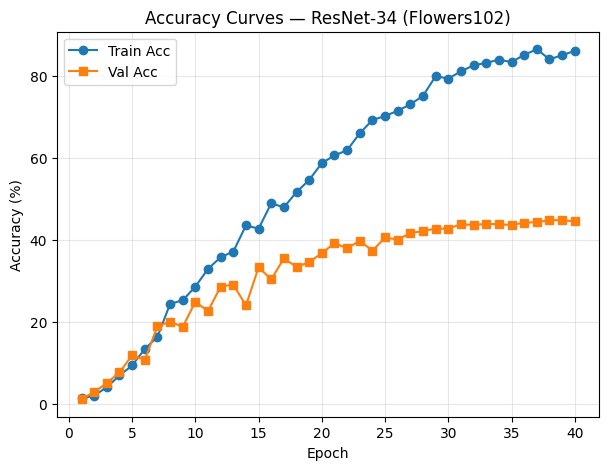

In [12]:
plt.figure(figsize=(7,5))
plt.plot(epochs_axis, np.array(best_hist["train_acc"])*100, label="Train Acc", marker="o")
plt.plot(epochs_axis, np.array(best_hist["val_acc"])*100,   label="Val Acc",   marker="s")
plt.title("Accuracy Curves — ResNet-34 (Flowers102)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Training vs Validation vs Test Loss

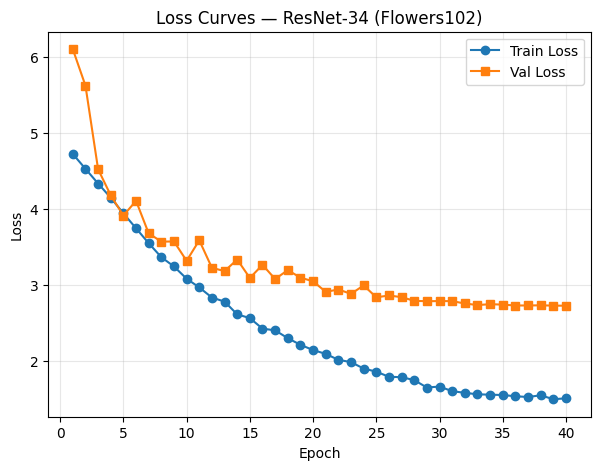

In [13]:
plt.figure(figsize=(7,5))
plt.plot(epochs_axis, best_hist["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs_axis, best_hist["val_loss"],   label="Val Loss",   marker="s")
plt.title("Loss Curves — ResNet-34 (Flowers102)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Confusion Matrix

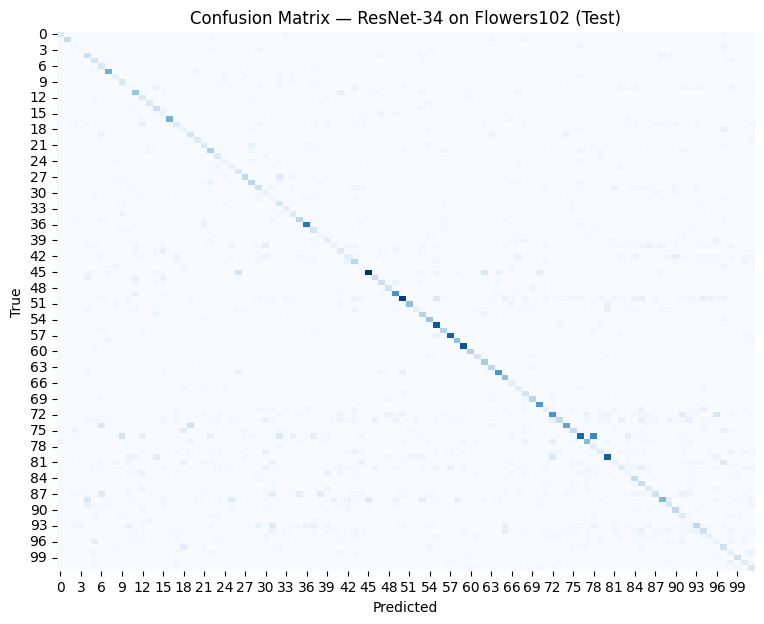

In [14]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9,7))
sns.heatmap(cm, cmap="Blues", cbar=False)
plt.title("Confusion Matrix — ResNet-34 on Flowers102 (Test)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

### Sample predictions grid

In [15]:
inv_norm = transforms.Normalize(mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
                                std=[1/0.229, 1/0.224, 1/0.225])

In [16]:
def show_samples(dl, model, n=8):
    model.eval()
    xb, yb = next(iter(dl))
    xb_s = xb[:n].to(device)
    with torch.no_grad():
        logits = model(xb_s)
    preds = logits.argmax(1).cpu().numpy()
    imgs  = xb[:n].clone()
    for i in range(n):
        imgs[i] = inv_norm(imgs[i])
    cols = 4; rows = math.ceil(n/cols)
    plt.figure(figsize=(cols*3, rows*3))
    for i in range(n):
        plt.subplot(rows, cols, i+1)
        img = np.transpose(imgs[i].numpy(), (1,2,0))
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.title(f"Pred: {preds[i]} | True: {yb[i].item()}", fontsize=9)
        plt.axis("off")
    plt.suptitle("Sample Predictions — ResNet-34 (Test Batch)")
    plt.tight_layout()
    plt.show()

show_samples(test_dl, model_best, n=8)

NameError: name 'test_dl' is not defined

In [ ]:
BEST_WEIGHTS_PTH = "a2_bonus_resnet_weighnts_pranayla_vpamulap.pth"
BEST_WEIGHTS_PKL = "a2_bonus_resnet_weighnts_pranayla_vpamulap.pkl"

torch.save(best_overall["state"], BEST_WEIGHTS_PTH)
import pickle
with open(BEST_WEIGHTS_PKL, "wb") as f:
    pickle.dump(best_overall["state"], f)

print(f"Saved best weights: {BEST_WEIGHTS_PTH} and {BEST_WEIGHTS_PKL}")

## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap | each 50% |
| 2 | pranayla & vpampulap | each 50% |
| 3 | pranayla & vpampulap | each 50% |
| 4 | pranayla & vpampulap | each 50%  |
| 5 | pranayla & vpampulap | each 50%  |